In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv("DATA/data.csv")

# Remove empty columns and identifier columns
df = df.dropna(axis=1, how="all")

if "id" in df.columns:
    df = df.drop(columns=["id"])

if "Unnamed: 32" in df.columns:
    df = df.drop(columns=["Unnamed: 32"])

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Dataset shape: (569, 31)
Columns: ['diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst']


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("All libraries installed successfully!")

Pandas: 3.0.6
NumPy: 2.5.3
Scikit-learn: 1.9.1
All libraries installed successfully!


In [20]:
TARGET_COLUMN = "diagnosis"

print("Selected target column:", TARGET_COLUMN)
print(df[TARGET_COLUMN].value_counts())

Selected target column: diagnosis
diagnosis
B    357
M    212
Name: count, dtype: int64


In [21]:
# Make a copy of the dataset
data = df.copy()

# Remove rows with missing target values
data = data.dropna(subset=[TARGET_COLUMN])

# Separate features and target
X = data.drop(columns=[TARGET_COLUMN])
y_original = data[TARGET_COLUMN]

print("Features shape:", X.shape)
print("Target shape:", y_original.shape)

Features shape: (569, 30)
Target shape: (569,)


In [22]:
from sklearn.preprocessing import LabelEncoder

# Remove rows where the target is missing
data = df.copy()
data = data.dropna(subset=[TARGET_COLUMN])

# Separate features and target
X = data.drop(columns=[TARGET_COLUMN])
y_original = data[TARGET_COLUMN]

# Convert target labels into numbers: 0 and 1
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_original)

# Logistic Regression here requires exactly 2 classes
if len(label_encoder.classes_) != 2:
    raise ValueError(
        f"Expected 2 target classes, but found: {label_encoder.classes_}"
    )

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nClass mapping:")
for i, class_name in enumerate(label_encoder.classes_):
    print(f"{class_name} -> {i}")

print("\nClass distribution:")
print(pd.Series(y).value_counts().sort_index())

Features shape: (569, 30)
Target shape: (569,)

Class mapping:
B -> 0
M -> 1

Class distribution:
0    357
1    212
Name: count, dtype: int64


In [23]:
from sklearn.model_selection import train_test_split

# First, separate 20% for final testing
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Split the remaining data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval,
    y_trainval,
    test_size=0.25,
    random_state=42,
    stratify=y_trainval
)

print("Training samples:", len(y_train))
print("Validation samples:", len(y_val))
print("Testing samples:", len(y_test))

Training samples: 341
Validation samples: 114
Testing samples: 114


In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

print("Numerical columns:", len(numeric_features))
print("Categorical columns:", len(categorical_features))

# Process numerical columns: fill missing values and scale
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Process categorical columns: fill missing values and encode text
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
transformers = []

if numeric_features:
    transformers.append(
        ("numeric", numeric_pipeline, numeric_features)
    )

if categorical_features:
    transformers.append(
        ("categorical", categorical_pipeline, categorical_features)
    )

if not transformers:
    raise ValueError("No usable feature columns were found.")

preprocessor = ColumnTransformer(transformers=transformers)

# Fit preprocessing ONLY on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same transformations to validation and test data
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("\nPreprocessing completed successfully!")
print("Training features:", X_train_processed.shape)
print("Validation features:", X_val_processed.shape)
print("Testing features:", X_test_processed.shape)

Numerical columns: 30
Categorical columns: 0

Preprocessing completed successfully!
Training features: (341, 30)
Validation features: (114, 30)
Testing features: (114, 30)


In [25]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

model.fit(X_train_processed, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [26]:
# Predict probabilities for the validation dataset
y_val_prob = model.predict_proba(X_val_processed)[:, 1]

# Predict classes using the default threshold of 0.5
y_val_pred = (y_val_prob >= 0.5).astype(int)

print("Actual labels:     ", y_val[:10])
print("Predicted labels:  ", y_val_pred[:10])
print("Predicted probabilities:", y_val_prob[:10].round(3))

Actual labels:      [0 1 0 0 0 0 0 1 1 1]
Predicted labels:   [0 1 0 0 0 0 0 1 1 0]
Predicted probabilities: [0.02  1.    0.    0.013 0.011 0.012 0.048 1.    1.    0.109]


In [27]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    classification_report
)

print("Accuracy:", round(accuracy_score(y_val, y_val_pred), 4))
print("Precision:", round(precision_score(y_val, y_val_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, y_val_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, y_val_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred,
    labels=[0, 1],
    target_names=[str(c) for c in label_encoder.classes_],
    zero_division=0
))

Accuracy: 0.9737
Precision: 0.9545
Recall: 0.9767
ROC-AUC: 0.9957

Classification Report:
              precision    recall  f1-score   support

           B       0.99      0.97      0.98        71
           M       0.95      0.98      0.97        43

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



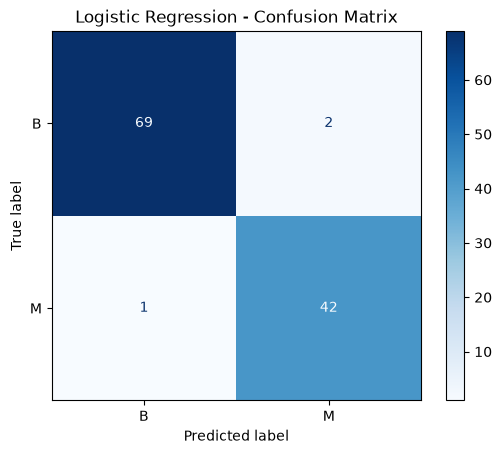

In [28]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_val, y_val_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[str(c) for c in label_encoder.classes_]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

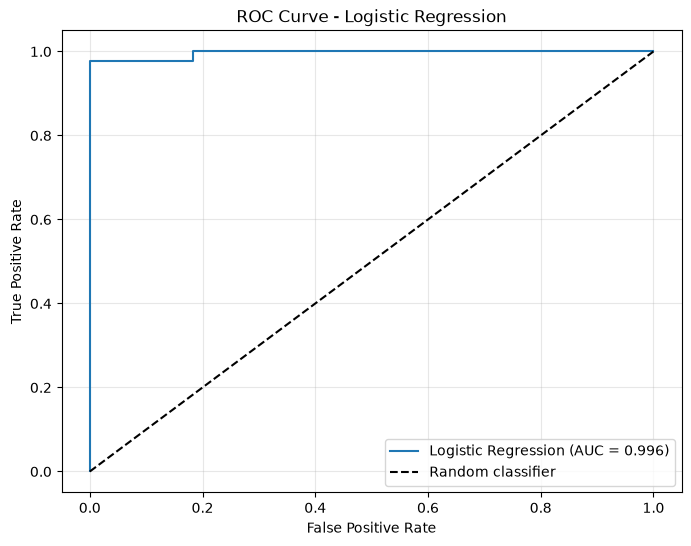

ROC-AUC Score: 0.9957


In [29]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_val, y_val_prob)

# Calculate AUC score
validation_auc = roc_auc_score(y_val, y_val_prob)

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {validation_auc:.3f})"
)
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("ROC-AUC Score:", round(validation_auc, 4))

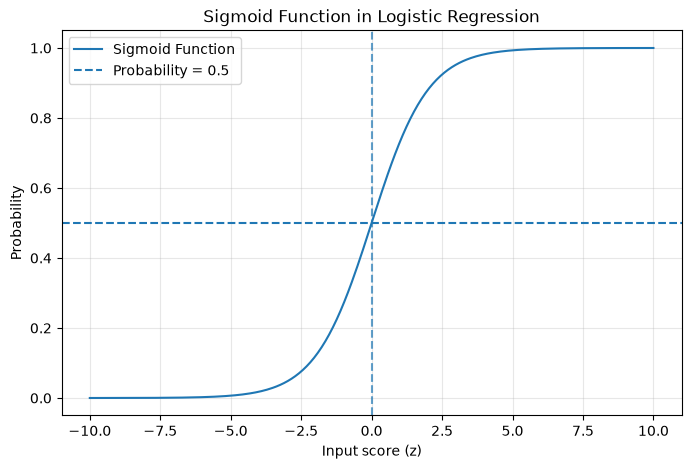

In [30]:
import numpy as np
import matplotlib.pyplot as plt

# Generate values
z = np.linspace(-10, 10, 300)

# Apply sigmoid function
sigmoid = 1 / (1 + np.exp(-z))

# Plot sigmoid curve
plt.figure(figsize=(8, 5))
plt.plot(z, sigmoid, label="Sigmoid Function")
plt.axhline(0.5, linestyle="--", label="Probability = 0.5")
plt.axvline(0, linestyle="--", alpha=0.7)

plt.xlabel("Input score (z)")
plt.ylabel("Probability")
plt.title("Sigmoid Function in Logistic Regression")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [31]:
from sklearn.metrics import accuracy_score, precision_score, recall_score
import pandas as pd

thresholds_to_test = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
results = []

for threshold in thresholds_to_test:
    predictions = (y_val_prob >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0)
    })

threshold_results = pd.DataFrame(results)
display(threshold_results.round(4))

,Threshold,Accuracy,Precision,Recall
0,0.2,0.9211,0.8400,0.9767
1,0.3,0.9561,0.9130,0.9767
2,0.4,0.9737,0.9545,0.9767
3,0.5,0.9737,0.9545,0.9767
4,0.6,0.9737,0.9545,0.9767
5,0.7,0.9912,1.0000,0.9767
6,0.8,0.9912,1.0000,0.9767


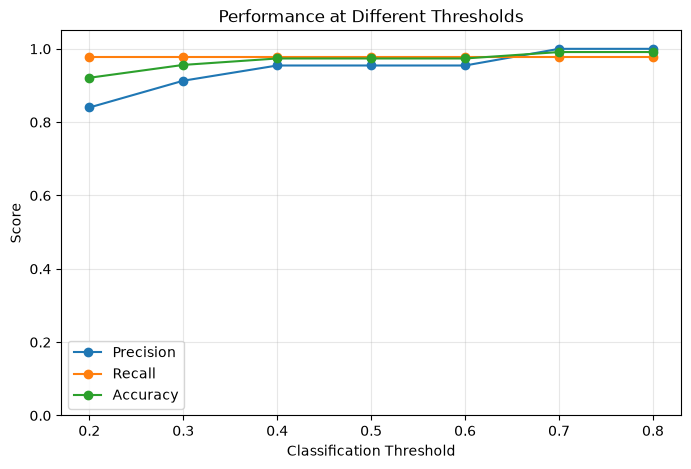

In [32]:
plt.figure(figsize=(8, 5))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Precision"],
    marker="o",
    label="Precision"
)
plt.plot(
    threshold_results["Threshold"],
    threshold_results["Recall"],
    marker="o",
    label="Recall"
)
plt.plot(
    threshold_results["Threshold"],
    threshold_results["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Performance at Different Thresholds")
plt.xticks(thresholds_to_test)
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

===== FINAL TEST RESULTS =====
Threshold: 0.5
Accuracy: 0.9737
Precision: 0.9756
Recall: 0.9524
ROC-AUC: 0.9954

Classification Report:
              precision    recall  f1-score   support

           B       0.97      0.99      0.98        72
           M       0.98      0.95      0.96        42

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



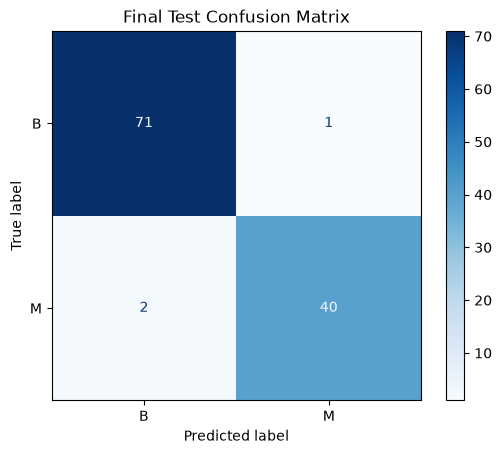

In [33]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Choose the final threshold.
# You can change this based on your validation results.
chosen_threshold = 0.5

# Predict probabilities on the test set
y_test_prob = model.predict_proba(X_test_processed)[:, 1]

# Convert probabilities to class predictions
y_test_pred = (y_test_prob >= chosen_threshold).astype(int)

# Display final test metrics
print("===== FINAL TEST RESULTS =====")
print("Threshold:", chosen_threshold)
print("Accuracy:", round(accuracy_score(y_test, y_test_pred), 4))
print("Precision:", round(precision_score(y_test, y_test_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_test_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_test_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1],
    target_names=[str(c) for c in label_encoder.classes_],
    zero_division=0
))

# Plot the test confusion matrix
cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[str(c) for c in label_encoder.classes_]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Final Test Confusion Matrix")
plt.show()

In [34]:
print("=" * 45)
print("TASK 4: LOGISTIC REGRESSION")
print("=" * 45)

print("Dataset: DATA/data.csv")
print("Target column:", TARGET_COLUMN)
print("Class 0:", label_encoder.classes_[0])
print("Class 1:", label_encoder.classes_[1])

print("\nFinal Test Performance")
print(f"Accuracy:  {accuracy_score(y_test, y_test_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_test_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_test_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_test_prob):.4f}")

print("\nTask 4 notebook execution completed!")

TASK 4: LOGISTIC REGRESSION
Dataset: DATA/data.csv
Target column: diagnosis
Class 0: B
Class 1: M

Final Test Performance
Accuracy:  0.9737
Precision: 0.9756
Recall:    0.9524
ROC-AUC:   0.9954

Task 4 notebook execution completed!
